# GARCH Model Fit and Volatility Estimation of the Euro Stoxx 50

This notebook is the first stage of the VaR-based portfolio project. It

1. downloads daily closing prices of the **Euro Stoxx 50** index,
2. checks the return series for the stylised facts that motivate GARCH (fat tails, volatility clustering, ARCH effects),
3. fits four candidate models on the **training window (start – 2017)** — GARCH(1,1) and GJR-GARCH(1,1,1), each with Normal and Student-t innovations — and selects one by information criteria,
4. produces **one-step-ahead conditional volatility forecasts** over the **test window (2018 – 2025)**, and
5. turns them into **1-day Value at Risk** at 95% and 99%, backtested with the Kupiec and Christoffersen tests against a rolling historical-simulation benchmark.

**Data source:** Yahoo Finance, ticker `^STOXX50E` (EURO STOXX 50 index, published by STOXX Ltd., part of Qontigo/Deutsche Börse Group), retrieved with the [`yfinance`](https://github.com/ranaroussi/yfinance) Python package. Yahoo's daily history for `^STOXX50E` begins on **30 Mar 2007**, so the training window starts there rather than in 1990.

In [1]:
# If needed: pip install numpy pandas scipy matplotlib statsmodels arch yfinance
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
TICKER      = "^STOXX50E"   # Euro Stoxx 50 on Yahoo Finance
START       = "1990-01-01"     # Yahoo returns data from 2007-03-30 onwards
END         = "2026-01-01"     # exclusive -> data through 31 Dec 2025
SPLIT       = "2018-01-01"     # first day of the out-of-sample test window
VAR_LEVELS  = [0.95, 0.99]
DATA_FILE   = Path("data/eurostoxx50_daily.csv")

## 1. Data

Prices are cached to `data/eurostoxx50_daily.csv` after the first download so the analysis is reproducible offline. Delete the file to refresh it.

In [3]:
if DATA_FILE.exists():
    prices = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True)["Close"]
else:
    raw = yf.download(TICKER, start=START, end=END, auto_adjust=False, progress=False)
    prices = raw["Close"][TICKER].rename("Close")
    prices.index.name = "Date"
    DATA_FILE.parent.mkdir(exist_ok=True)
    prices.to_frame().to_csv(DATA_FILE)

prices = prices.dropna()
prices = prices[~prices.index.duplicated()]
print(f"{len(prices)} trading days: {prices.index[0].date()} -> {prices.index[-1].date()}")
prices.tail()

4701 trading days: 2007-03-30 -> 2025-12-30


Date
2025-12-19   5760.3501
2025-12-22   5743.6899
2025-12-23   5749.2798
2025-12-29   5751.7100
2025-12-30   5796.2202
Name: Close, dtype: float64

GARCH models are fitted to **daily log returns in percent**, $r_t = 100 \cdot \ln(P_t / P_{t-1})$. Scaling by 100 keeps the optimiser well-conditioned.

Train: 2007-04-02 -> 2017-12-29  (2692 obs)
Test : 2018-01-03 -> 2025-12-30  (2008 obs)


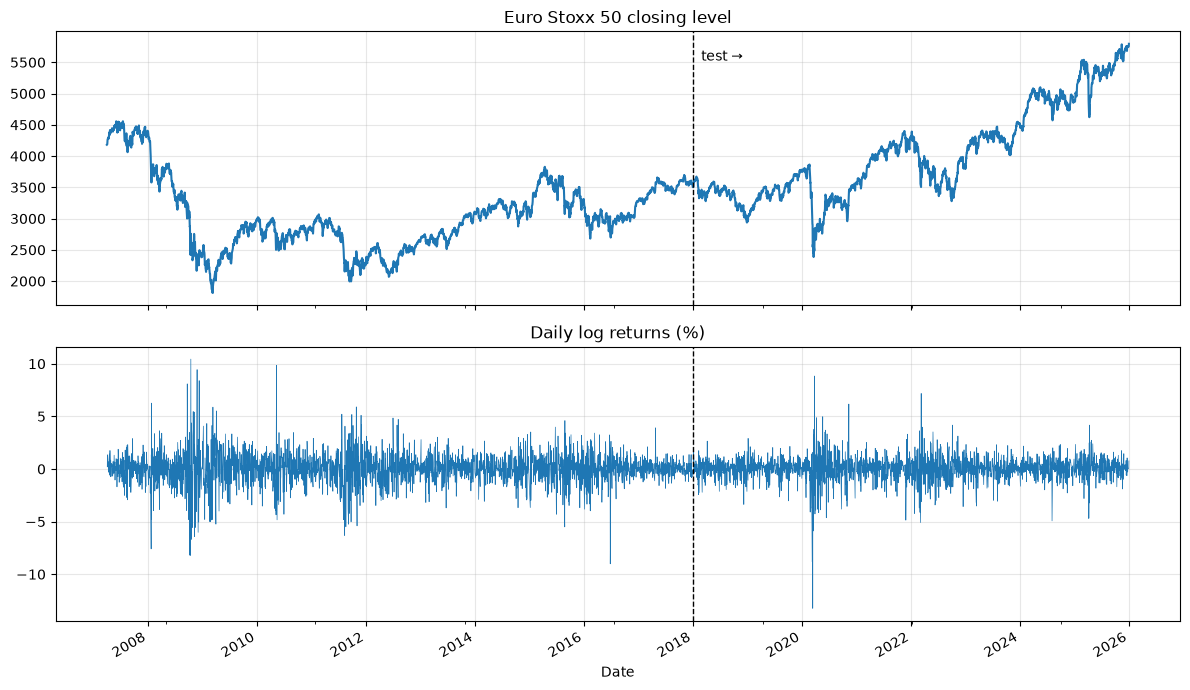

In [4]:
returns = (100 * np.log(prices).diff()).dropna().rename("r")
train = returns[returns.index < SPLIT]
test  = returns[returns.index >= SPLIT]

print(f"Train: {train.index[0].date()} -> {train.index[-1].date()}  ({len(train)} obs)")
print(f"Test : {test.index[0].date()} -> {test.index[-1].date()}  ({len(test)} obs)")

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
prices.plot(ax=ax[0], color="C0", title="Euro Stoxx 50 closing level")
returns.plot(ax=ax[1], color="C0", lw=0.5, title="Daily log returns (%)")
for a in ax:
    a.axvline(pd.Timestamp(SPLIT), color="k", ls="--", lw=1)
ax[0].text(pd.Timestamp(SPLIT), ax[0].get_ylim()[1] * 0.95, "  test →", va="top")
plt.tight_layout()

## 2. Stylised facts

Before fitting anything we check the two properties that make a constant-variance model inappropriate:

* **Fat tails** – excess kurtosis and a rejected Jarque–Bera normality test.
* **Volatility clustering** – little autocorrelation in returns, but strong autocorrelation in *squared* returns, confirmed by Ljung–Box and Engle's ARCH-LM tests.

In [5]:
def describe(x):
    jb = stats.jarque_bera(x)
    return pd.Series({
        "obs": len(x),
        "mean (%)": x.mean(),
        "std (%)": x.std(),
        "ann. vol (%)": x.std() * np.sqrt(252),
        "skew": stats.skew(x),
        "excess kurtosis": stats.kurtosis(x),
        "min (%)": x.min(),
        "max (%)": x.max(),
        "Jarque-Bera p": jb.pvalue,
    })

pd.DataFrame({"full": describe(returns), "train": describe(train), "test": describe(test)})

,full,train,test
obs,4700.0000,2692.0000,2008.0000
mean (%),0.0069,-0.0066,0.0251
std (%),1.3821,1.5065,1.1953
ann. vol (%),21.9394,23.9142,18.9744
skew,-0.3141,-0.0673,-0.9295
excess kurtosis,7.7091,5.5016,13.1096
min (%),-13.2405,-9.0110,-13.2405
max (%),10.4376,10.4376,8.8343
Jarque-Bera p,0.0000,0.0000,0.0000


Ljung-Box on returns:
     lb_stat  lb_pvalue
10  32.9668     0.0003
20  46.4144     0.0007 

Ljung-Box on squared returns:
      lb_stat  lb_pvalue
10 1075.0207     0.0000
20 1666.5385     0.0000 

Engle ARCH-LM (10 lags): stat = 417.0, p = 2.24e-83


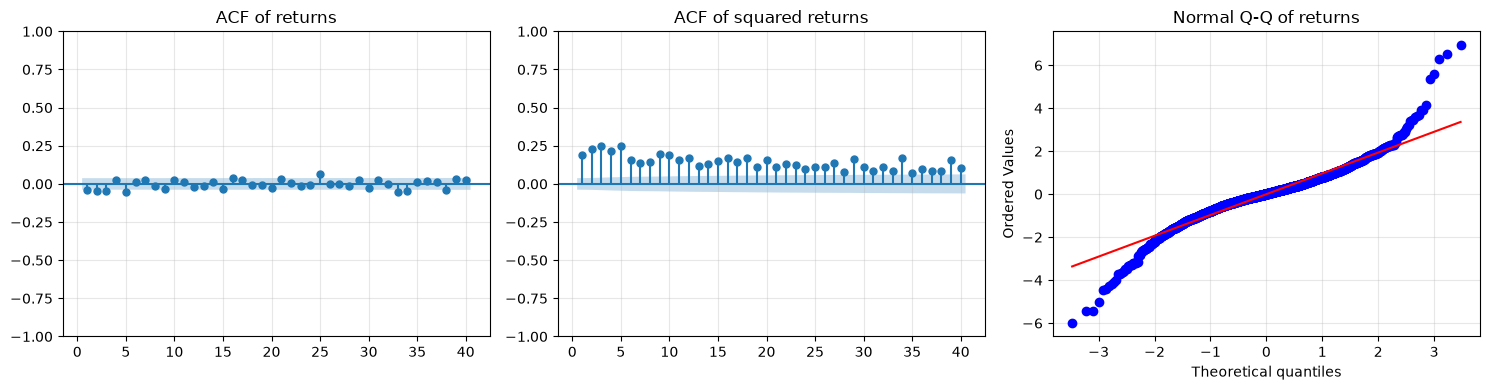

In [6]:
lb_r  = acorr_ljungbox(train, lags=[10, 20], return_df=True)
lb_r2 = acorr_ljungbox(train**2, lags=[10, 20], return_df=True)
lm_stat, lm_p, _, _ = het_arch(train - train.mean(), nlags=10)

print("Ljung-Box on returns:\n", lb_r, "\n")
print("Ljung-Box on squared returns:\n", lb_r2, "\n")
print(f"Engle ARCH-LM (10 lags): stat = {lm_stat:.1f}, p = {lm_p:.2e}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_acf(train, lags=40, ax=ax[0], title="ACF of returns", zero=False)
plot_acf(train**2, lags=40, ax=ax[1], title="ACF of squared returns", zero=False)
z = (train - train.mean()) / train.std()
stats.probplot(z, dist="norm", plot=ax[2]); ax[2].set_title("Normal Q-Q of returns")
plt.tight_layout()

Squared returns are strongly autocorrelated and the ARCH-LM test rejects homoskedasticity decisively, while the Q-Q plot shows heavy tails on both sides. A GARCH-type model with a fat-tailed innovation distribution is warranted.

## 3. Model estimation (training window)

All models use a constant mean, $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$:

| Model | Variance equation |
|---|---|
| GARCH(1,1) | $\sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$ |
| GJR-GARCH(1,1,1) | $\sigma_t^2 = \omega + (\alpha + \gamma\,\mathbb{1}[\varepsilon_{t-1}<0])\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$ |

$\gamma > 0$ captures the **leverage effect**: bad news raises volatility more than good news of the same size. Each is estimated with $z_t \sim N(0,1)$ and with a standardised Student-$t$.

To make the out-of-sample step easy, every model is built on the **full** return series but estimated with `last_obs=SPLIT`, so only training data enters the likelihood.

In [7]:
SPECS = {
    "GARCH-N":   dict(vol="GARCH", p=1, o=0, q=1, dist="normal"),
    "GARCH-t":   dict(vol="GARCH", p=1, o=0, q=1, dist="t"),
    "GJR-N":     dict(vol="GARCH", p=1, o=1, q=1, dist="normal"),
    "GJR-t":     dict(vol="GARCH", p=1, o=1, q=1, dist="t"),
}

models, fits = {}, {}
for name, spec in SPECS.items():
    models[name] = arch_model(returns, mean="Constant", **spec)
    fits[name] = models[name].fit(last_obs=SPLIT, disp="off")

def persistence(res):
    p = res.params
    return p["alpha[1]"] + p["beta[1]"] + 0.5 * p.get("gamma[1]", 0.0)

comparison = pd.DataFrame({
    name: {
        "log-lik": r.loglikelihood,
        "AIC": r.aic,
        "BIC": r.bic,
        "persistence": persistence(r),
        "nu (t dof)": r.params.get("nu", np.nan),
    }
    for name, r in fits.items()
}).T
comparison.sort_values("BIC")

,log-lik,AIC,BIC,persistence,nu (t dof)
GJR-t,-4371.9030,8755.8059,8791.1942,0.9908,7.6896
GJR-N,-4420.9359,8851.8719,8881.3621,0.9886,NaN
GARCH-t,-4433.0274,8876.0548,8905.5450,0.9957,6.7528
GARCH-N,-4491.1025,8990.2051,9013.7972,0.9902,NaN


In [8]:
best_name = comparison["BIC"].idxmin()
best = fits[best_name]
print(f"Selected model (lowest BIC): {best_name}\n")
print(best.summary())

Selected model (lowest BIC): GJR-t

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                            r   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -4371.90
Distribution:      Standardized Student's t   AIC:                           8755.81
Method:                  Maximum Likelihood   BIC:                           8791.19
                                              No. Observations:                 2692
Date:                      Wed, Nov 18 2026   Df Residuals:                     2691
Time:                              17:51:55   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------

### Interpreting the selected model

* **Persistence** $\alpha + \beta + \gamma/2$ close to 1 means shocks to volatility decay slowly.
* **Half-life** $\ln(0.5)/\ln(\text{persistence})$ is the number of days for a volatility shock to halve.
* **Long-run volatility** $\sqrt{\omega / (1-\text{persistence})}$ is the level the forecasts revert to.

In [9]:
p = best.params
pers = persistence(best)
half_life = np.log(0.5) / np.log(pers)
lr_var = p["omega"] / (1 - pers)

pd.Series({
    "persistence": pers,
    "half-life (days)": half_life,
    "long-run daily vol (%)": np.sqrt(lr_var),
    "long-run annual vol (%)": np.sqrt(lr_var * 252),
    "leverage gamma": p.get("gamma[1]", np.nan),
    "Student-t dof": p.get("nu", np.nan),
}).to_frame(best_name)

,GJR-t
persistence,0.9908
half-life (days),74.7140
long-run daily vol (%),1.7297
long-run annual vol (%),27.4576
leverage gamma,0.1976
Student-t dof,7.6896


### Residual diagnostics

If the model captured the volatility dynamics, standardised residuals $\hat z_t = \hat\varepsilon_t/\hat\sigma_t$ should show no remaining autocorrelation in their squares.

Ljung-Box on squared standardised residuals:
    lb_stat  lb_pvalue
10  10.4635     0.4008
20  19.9264     0.4625

ARCH-LM on standardised residuals (10 lags): stat = 11.20, p = 0.342


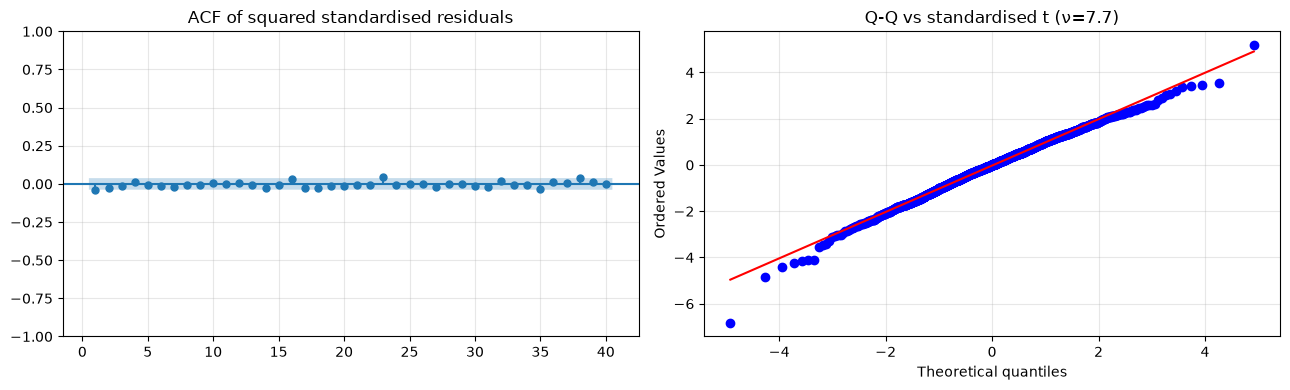

In [10]:
std_resid = (best.resid / best.conditional_volatility).dropna()
print("Ljung-Box on squared standardised residuals:")
print(acorr_ljungbox(std_resid**2, lags=[10, 20], return_df=True))
lm_stat, lm_p, _, _ = het_arch(std_resid, nlags=10)
print(f"\nARCH-LM on standardised residuals (10 lags): stat = {lm_stat:.2f}, p = {lm_p:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(std_resid**2, lags=40, ax=ax[0], zero=False, title="ACF of squared standardised residuals")
if "nu" in p:
    nu = p["nu"]
    dist = stats.t(df=nu, scale=np.sqrt((nu - 2) / nu))   # unit-variance t
    stats.probplot(std_resid, dist=dist, plot=ax[1]); ax[1].set_title(f"Q-Q vs standardised t (ν={nu:.1f})")
else:
    stats.probplot(std_resid, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q vs Normal")
plt.tight_layout()

### In-sample conditional volatility

Annualised conditional volatility $\hat\sigma_t\sqrt{252}$ over the training window. The 2008 global financial crisis and later stress episodes appear as clear volatility clusters.

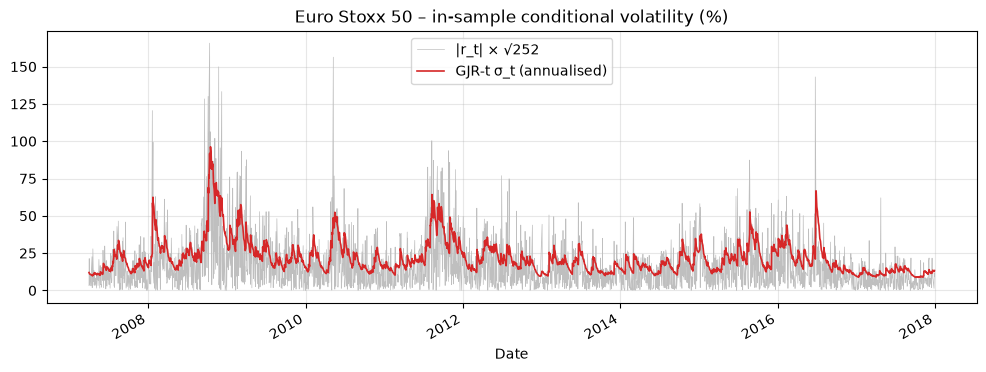

In [11]:
in_vol = best.conditional_volatility.dropna() * np.sqrt(252)
ax = (train.abs() * np.sqrt(252)).plot(color="0.75", lw=0.5, label="|r_t| × √252")
in_vol.plot(ax=ax, color="C3", lw=1.2, label=f"{best_name} σ_t (annualised)")
ax.set_title("Euro Stoxx 50 – in-sample conditional volatility (%)"); ax.legend()

## 4. Out-of-sample volatility forecasts (2018 – 2025)

Parameters stay fixed at their training estimates. The variance recursion is run forward through the test window, so each forecast $\hat\sigma_{t+1|t}$ uses only information up to day $t$. `forecast(start=…)` returns the forecast made *at* day $t$ for day $t+1$, so it is shifted by one day to line up with the realised return.

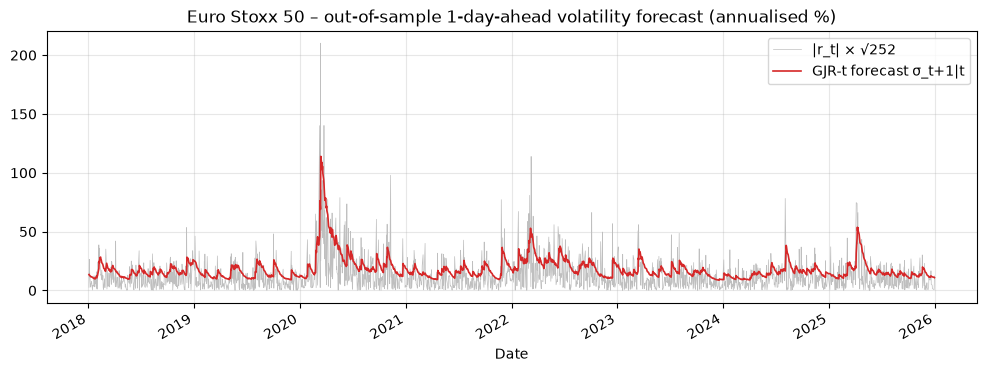

In [12]:
def one_step_forecasts(res, start):
    fc = res.forecast(horizon=1, start=start, reindex=False)
    mu  = fc.mean["h.1"].shift(1)
    var = fc.variance["h.1"].shift(1)
    out = pd.DataFrame({"mu": mu, "sigma": np.sqrt(var)}).dropna()
    return out.loc[out.index >= SPLIT]

# start one day before the split so the first test day gets a forecast
start = train.index[-1]
oos = {name: one_step_forecasts(r, start) for name, r in fits.items()}
best_oos = oos[best_name].join(test)

ax = (best_oos["r"].abs() * np.sqrt(252)).plot(color="0.75", lw=0.5, label="|r_t| × √252")
(best_oos["sigma"] * np.sqrt(252)).plot(ax=ax, color="C3", lw=1.2, label=f"{best_name} forecast σ_t+1|t")
ax.set_title("Euro Stoxx 50 – out-of-sample 1-day-ahead volatility forecast (annualised %)"); ax.legend()

A quick accuracy check: compare forecast variance with the realised squared return using **MSE** and **QLIKE** (the loss function most robust to noise in the volatility proxy; lower is better).

In [13]:
def vol_losses(df):
    h, r2 = df["sigma"] ** 2, (df["r"] - df["mu"]) ** 2
    return pd.Series({"MSE": ((r2 - h) ** 2).mean(), "QLIKE": (np.log(h) + r2 / h).mean()})

pd.DataFrame({name: vol_losses(f.join(test)) for name, f in oos.items()}).T.sort_values("QLIKE")

,MSE,QLIKE
GJR-N,28.0241,1.0181
GJR-t,28.4195,1.0183
GARCH-N,27.8213,1.0595
GARCH-t,27.9393,1.0654


## 5. Value at Risk and backtesting

The one-day VaR at confidence level $c$ (reported as a positive loss in %) is

$$\text{VaR}^{c}_{t+1} = -\left(\hat\mu + \hat\sigma_{t+1|t}\, q_{1-c}\right),$$

where $q_{1-c}$ is the $(1-c)$ quantile of the fitted innovation distribution. A **violation** occurs when $r_{t+1} < -\text{VaR}_{t+1}$.

**Benchmark:** rolling 250-day historical simulation (empirical quantile of the last year of returns), the standard non-parametric approach.

**Backtests**

* **Kupiec POF** – is the violation rate equal to $1-c$? (unconditional coverage)
* **Christoffersen** – are violations independent, i.e. not bunched together? (independence)
* **Conditional coverage** – both jointly, $LR_{cc} = LR_{pof} + LR_{ind} \sim \chi^2_2$.

In [14]:
def garch_var(res, model, fc, c):
    names = model.distribution.parameter_names()          # [] for Normal, ["nu"] for Student-t
    q = model.distribution.ppf(1 - c, res.params[names].values if names else None)
    return -(fc["mu"] + fc["sigma"] * q)

def hist_var(r, c, window=250):
    return -r.rolling(window).quantile(1 - c).shift(1)

def kupiec(hits, p):
    n, x = len(hits), hits.sum()
    pi = x / n
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return lr, 1 - stats.chi2.cdf(lr, 1)

def christoffersen(hits):
    h = hits.astype(int).values
    prev, curr = h[:-1], h[1:]
    n00 = ((prev == 0) & (curr == 0)).sum(); n01 = ((prev == 0) & (curr == 1)).sum()
    n10 = ((prev == 1) & (curr == 0)).sum(); n11 = ((prev == 1) & (curr == 1)).sum()
    pi0 = n01 / (n00 + n01) if n00 + n01 else 0
    pi1 = n11 / (n10 + n11) if n10 + n11 else 0
    pi  = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll = lambda k, q: k * np.log(q) if k else 0.0          # treats 0·log(0) as 0
    l0 = ll(n00 + n10, 1 - pi) + ll(n01 + n11, pi)
    l1 = ll(n00, 1 - pi0) + ll(n01, pi0) + ll(n10, 1 - pi1) + ll(n11, pi1)
    lr = -2 * (l0 - l1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def backtest(r, var, c):
    df = pd.concat([r, var.rename("VaR")], axis=1).dropna()
    hits = df["r"] < -df["VaR"]
    lr_pof, p_pof = kupiec(hits, 1 - c)
    lr_ind, p_ind = christoffersen(hits)
    lr_cc = lr_pof + lr_ind
    return {
        "days": len(df),
        "expected": (1 - c) * len(df),
        "violations": int(hits.sum()),
        "rate (%)": 100 * hits.mean(),
        "Kupiec p": p_pof,
        "Christoffersen p": p_ind,
        "CC p": 1 - stats.chi2.cdf(lr_cc, 2),
        "avg VaR (%)": df["VaR"].mean(),
    }

In [15]:
var_series, rows = {}, []
for c in VAR_LEVELS:
    for name, res in fits.items():
        v = garch_var(res, models[name], oos[name], c)
        var_series[(name, c)] = v
        rows.append({"model": name, "level": f"{c:.0%}", **backtest(test, v, c)})
    hv = hist_var(returns, c).loc[test.index]
    var_series[("HistSim-250", c)] = hv
    rows.append({"model": "HistSim-250", "level": f"{c:.0%}", **backtest(test, hv, c)})

bt = pd.DataFrame(rows).set_index(["level", "model"])
bt.style.format({
    "expected": "{:.1f}", "rate (%)": "{:.2f}", "avg VaR (%)": "{:.2f}",
    "Kupiec p": "{:.3f}", "Christoffersen p": "{:.3f}", "CC p": "{:.3f}",
}).map(lambda v: "color: #c0392b; font-weight: bold" if isinstance(v, float) and v < 0.05 else "",
       subset=["Kupiec p", "Christoffersen p", "CC p"])

p-values below 0.05 (red) reject correct coverage / independence at the 5% level. A good VaR model has a violation rate close to the nominal level **and** violations that are not clustered.

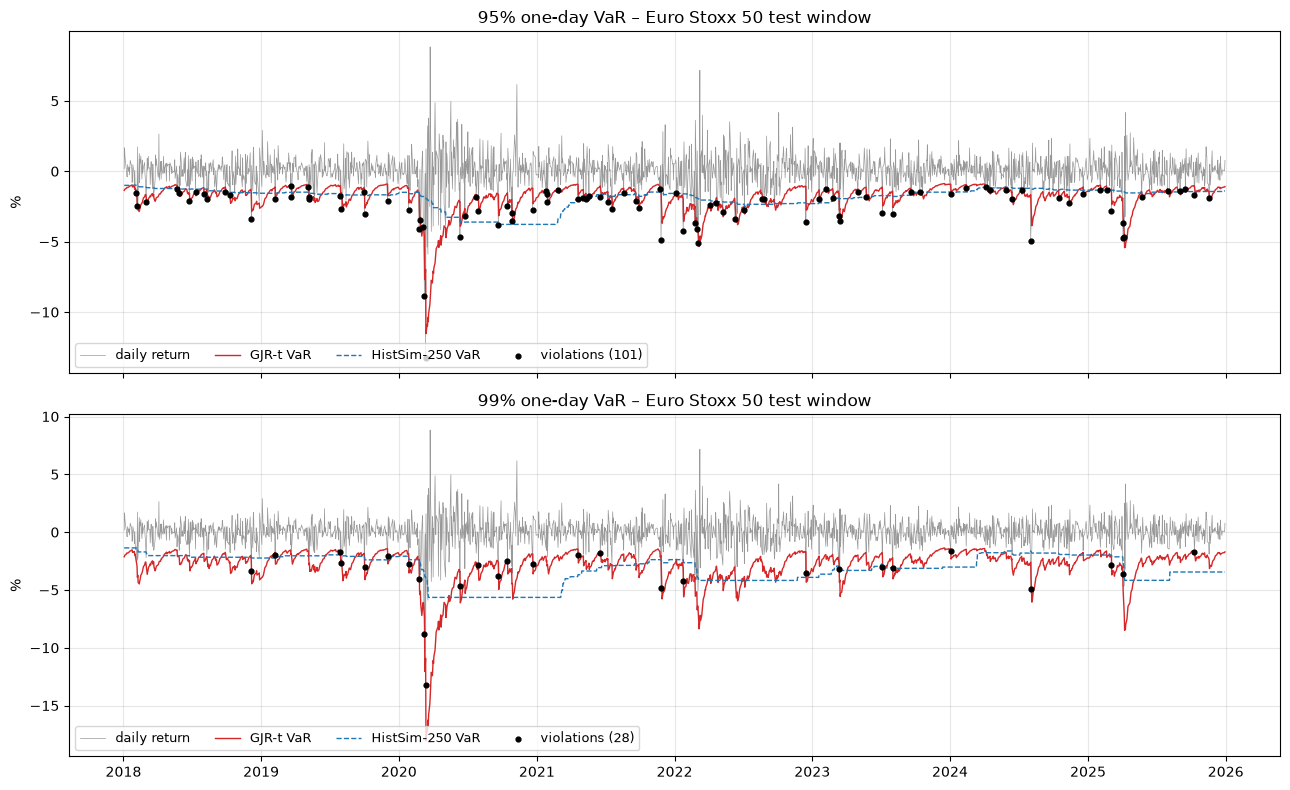

In [16]:
fig, axes = plt.subplots(len(VAR_LEVELS), 1, figsize=(13, 8), sharex=True)
for ax, c in zip(axes, VAR_LEVELS):
    v_g = var_series[(best_name, c)]
    v_h = var_series[("HistSim-250", c)]
    ax.plot(test.index, test, color="0.6", lw=0.5, label="daily return")
    ax.plot(v_g.index, -v_g, color="C3", lw=1, label=f"{best_name} VaR")
    ax.plot(v_h.index, -v_h, color="C0", lw=1, ls="--", label="HistSim-250 VaR")
    hits = test < -v_g.reindex(test.index)
    ax.scatter(test.index[hits], test[hits], color="k", s=12, zorder=3, label=f"violations ({hits.sum()})")
    ax.set_title(f"{c:.0%} one-day VaR – Euro Stoxx 50 test window"); ax.set_ylabel("%")
    ax.legend(loc="lower left", ncol=4, fontsize=9)
plt.tight_layout()

## 6. Summary and export

The table below collects the key numbers for the selected model. Conditional volatility and VaR forecasts are saved to `data/eurostoxx50_garch_forecasts.csv` for the portfolio-construction stage, where they will be combined with the NIFTY 50 and S&P 500.

In [17]:
summary = pd.Series({
    "selected model": best_name,
    "training window": f"{train.index[0].date()} – {train.index[-1].date()}",
    "test window": f"{test.index[0].date()} – {test.index[-1].date()}",
    "persistence": round(pers, 4),
    "half-life (days)": round(half_life, 1),
    "long-run annual vol (%)": round(np.sqrt(lr_var * 252), 2),
    "mean forecast annual vol, test (%)": round(best_oos["sigma"].mean() * np.sqrt(252), 2),
    **{f"{c:.0%} VaR violation rate (%)": round(bt.loc[(f'{c:.0%}', best_name), 'rate (%)'], 2) for c in VAR_LEVELS},
    **{f"{c:.0%} VaR Kupiec p": round(bt.loc[(f'{c:.0%}', best_name), 'Kupiec p'], 3) for c in VAR_LEVELS},
})
display(summary.to_frame("Euro Stoxx 50"))

export = best_oos.rename(columns={"r": "return_pct", "sigma": "sigma_pct", "mu": "mu_pct"})
for c in VAR_LEVELS:
    export[f"VaR_{int(c*100)}_pct"] = var_series[(best_name, c)]
export.to_csv("data/eurostoxx50_garch_forecasts.csv")
export.tail()

,Euro Stoxx 50
selected model,GJR-t
training window,2007-04-02 – 2017-12-29
test window,2018-01-03 – 2025-12-30
persistence,0.9908
half-life (days),74.7000
long-run annual vol (%),27.4600
"mean forecast annual vol, test (%)",18.2300
95% VaR violation rate (%),5.0300
99% VaR violation rate (%),1.3900
95% VaR Kupiec p,0.9510


,mu_pct,sigma_pct,return_pct,VaR_95_pct,VaR_99_pct
Date,,,,,
2025-12-19,0.0154,0.7555,0.3241,1.1994,1.8851
2025-12-22,0.0154,0.7326,-0.2896,1.1626,1.8276
2025-12-23,0.0154,0.7244,0.0973,1.1494,1.8069
2025-12-29,0.0154,0.7040,0.0423,1.1167,1.7558
2025-12-30,0.0154,0.6854,0.7709,1.0867,1.7088
